In [1]:
import numpy as np
import numpy.ma as ma
from netCDF4 import Dataset
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
import matplotlib.ticker as mticker
from matplotlib import colors

import matplotlib.gridspec as gridspec
import xarray as xr
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.arima_process import ArmaProcess
import matplotlib.colors as mcolors

import cartopy
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.crs as ccrs
from scipy import signal
from scipy.signal import periodogram
import eofs
import iris
import iris.quickplot as qplt 
import iris.plot as iplt
iris.FUTURE.netcdf_promote=True
import iris.coord_categorisation

import matplotlib.patches as mpatches
from matplotlib.path import Path

from iris.analysis import stats
from iris.analysis import maths
import glob

/apps/developers/compilers/canopy3/2.1.3/1/bit-64/Canopy/edm/envs/User/lib/python3.5/site-packages/matplotlib/ticker.py:1693: UserWarning: Steps argument should be a sequence of numbers
increasing from 1 to 10, inclusive. Behavior with
values outside this range is undefined, and will
raise a ValueError in future versions of mpl.
  warnings.warn('Steps argument should be a sequence of numbers\n'


In [2]:
## Upload PI
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/work/nc/xpzed/datam/pg/'
path3 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_pi = ['no3_Oyr_ACCESS-ESM1-5_piControl_r1i1p1f1_gn_1001-1100_reg_360x385_100yr_mean_intlevel.nc',
                   'otracer3_no3_xpzed_pg_5021-5120_regridded_385x360_ann_mean_intlevel.nc',
                   'no3_Omon_IPSL-CM6A-LR_piControl_r1i1p1f1_gn_375001-384912_reg_360x385_100yr_mean_intlevel.nc',
                   'H0K_ym_6401_6500.codeNO3.100yrsmean_reg_360x385_intlevel.nc',
                   'no3_Omon_MIROC-ES2L_piControl_r1i1p1f2_gr1_225001-234912_reg_360x385_100yr_mean_intlevel.nc',
                   'no3_Oyr_NorESM1-F_piControl_r1i1p1f1_gr_1601-1700_reg_360x385_100yr_mean_intlevel.nc',
                   'no3_Omon_NorESM2-LM_piControl_r1i1p1f1_gr_200101-210012_reg_360x385_100yr_mean_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3')]
PI_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_pi[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path3+names_models_pi[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_pi[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    PI_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'no3'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'no3'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conver

In [3]:
## Upload LIG
path = '/nfs/hera1/ee22kvcs/PMIP4/'
path2 = '/nfs/hera1/ee22kvcs/work/nc/xpzec/datam/pg/'
path3 = '/nfs/hera1/ee22kvcs/KCM/'
models = [ 'ACCESS-ESM1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
names_models_lig = ['no3_Omon_ACCESS-ESM1-5_lig127k_r1i1p1f1_gn_100101-110012_reg_360x385_100yr_mean_intlevel.nc',
                    'otracer3_no3_xpzeco_pg_6651-6750_regridded_385x360_ann_mean_intlevel.nc',
                    'no3_Omon_IPSL-CM6A-LR_lig127k_r1i1p1f1_gn_230001-239912_100yr_mean_reg_360x385_v2_intlevel.nc',
                    'E7C_ym_4901_5000.codeNO3.100yrsmean_reg_360x385_intlevel.nc',
                    'no3_Omon_MIROC-ES2L_lig127k_r1i1p1f2_gr1_330001-339912_reg_360x385_100yr_mean_intlevel.nc',
                    'no3_Oyr_NorESM1-F_lig127k_r1i1p1f1_gr_1601-1700_reg_360x385_100yr_mean_intlevel.nc',
                    'no3_Omon_NorESM2-LM_lig127k_r1i1p1f1_gr_210101-220012_reg_360x385_100yr_mean_intlevel.nc']

constraints = [iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'otracer3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'var1'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3'),
               iris.Constraint(cube_func=lambda cube: cube.var_name == 'no3')]
LIG_models = []
for i in range(np.size(models)):
    if i == 1:
        uploaded_cubes = iris.load_cube(path2+names_models_lig[i], constraints[i])
    elif i == 3:
        uploaded_cubes = iris.load_cube(path3+names_models_lig[i], constraints[i])
    else:
        uploaded_cubes = iris.load_cube(path+names_models_lig[i], constraints[i])
    uploaded_cubes = iris.util.squeeze(uploaded_cubes)
    LIG_models.append(uploaded_cubes)

/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'areacello', referenced by netCDF variable 'no3'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/cf.py:798: UserWarning: Missing CF-netCDF measure variable 'volcello', referenced by netCDF variable 'no3'
  warnings.warn(message % (variable_name, nc_var_name))
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conversion of the second argument of issubdtype from `str` to `str` is deprecated. In future, it will be treated as `np.str_ == np.dtype(str).type`.
  if np.issubdtype(cf_var.dtype, np.str):
/apps/developers/libraries/python-libs/1.6/1/bit-64-python3-3.5.2/lib/iris/fileformats/_pyke_rules/compiled_krb/fc_rules_cf_fc.py:1813: FutureWarning: Conver

### Integrate over sfc to 100m depth (level 25)

In [5]:
def integrate_nutrients(cube_list):
    integrated_list = []
    
    for cube in cube_list:
        # Find the vertical coordinate
        vertical_coords = [c for c in cube.coords() if c.shape == (76,)]
        
        if not vertical_coords:
            integrated_list.append(cube)# 2D cube
            continue
        
        vert_coord = vertical_coords[0]
        vert_dim = cube.coord_dims(vert_coord)[0]
        
        # Slice levels 5 to 25
        slices = [slice(None)] * cube.ndim
        slices[vert_dim] = slice(5, 25+1)
        sub_cube = cube[tuple(slices)]
        
        # Get the vertical coordinate values
        vert_values = vert_coord.points[5:25+1]  # shape: (21,)
        
        # Compute layer thicknesses using numpy trapezoid-style weights
        # Each level gets weight = 0.5*(next - prev), edge levels get half intervals
        n_levels = len(vert_values)
        weights = np.zeros(n_levels)
        
        for i in range(n_levels):
            if i == 0:
                weights[i] = 0.5 * abs(vert_values[1] - vert_values[0])
            elif i == n_levels - 1:
                weights[i] = 0.5 * abs(vert_values[-1] - vert_values[-2])
            else:
                weights[i] = 0.5 * abs(vert_values[i+1] - vert_values[i-1])
        
        # Broadcast weights to match cube shape
        weight_shape = [1] * sub_cube.ndim
        weight_shape[vert_dim] = n_levels
        weights_broadcast = weights.reshape(weight_shape)
        
        # Weighted sum along the vertical dimension
        integrated_data = np.sum(sub_cube.data * weights_broadcast, axis=vert_dim)
        
        # Build a new cube (2D)
        new_coords = []
        for coord in sub_cube.coords():
            if coord.shape == (76,) or coord.shape == (21,):
                continue
            dims = sub_cube.coord_dims(coord)
            if not dims:  # skip scalar coords
                continue
            new_dims = tuple(d - 1 if d > vert_dim else d for d in dims)
            if isinstance(coord, iris.coords.DimCoord):
                new_coords.append((coord, new_dims[0]))
            else:
                new_coords.append((coord, new_dims))
        
        integrated_cube = iris.cube.Cube(
            integrated_data,
            standard_name=cube.standard_name,
            long_name=cube.long_name,
            var_name=cube.var_name,
            units=cube.units,
            attributes=cube.attributes,
            cell_methods=cube.cell_methods,
            dim_coords_and_dims=[(c, d) for c, d in new_coords if isinstance(c, iris.coords.DimCoord)],
            aux_coords_and_dims=[(c, d) for c, d in new_coords if isinstance(c, iris.coords.AuxCoord)])
        
        integrated_list.append(integrated_cube)
    
    return integrated_list

In [6]:
PI_integrated = integrate_nutrients(PI_models)
LIG_integrated = integrate_nutrients(LIG_models)

In [7]:
Dif_integrated = []
for i in range(len(PI_integrated)):
    if i == 1:
        diff_data = (LIG_integrated[i].data - PI_integrated[i].data)*1
    elif i == 3:
        diff_data = (LIG_integrated[i].data - PI_integrated[i].data)*150.94*1e3
    else:
        diff_data = (LIG_integrated[i].data - PI_integrated[i].data)*1e3
    diff_cube = PI_integrated[i].copy()
    diff_cube.data = diff_data
    Dif_integrated.append(diff_cube)

### Plot integrated 0-100 m NO3

Self-intersection at or near point -180 -15.296541183562114
Self-intersection at or near point -180 -4.6877716987227691
Self-intersection at or near point -180 -29.5743529816909
Self-intersection at or near point -180 -36.97679601983134


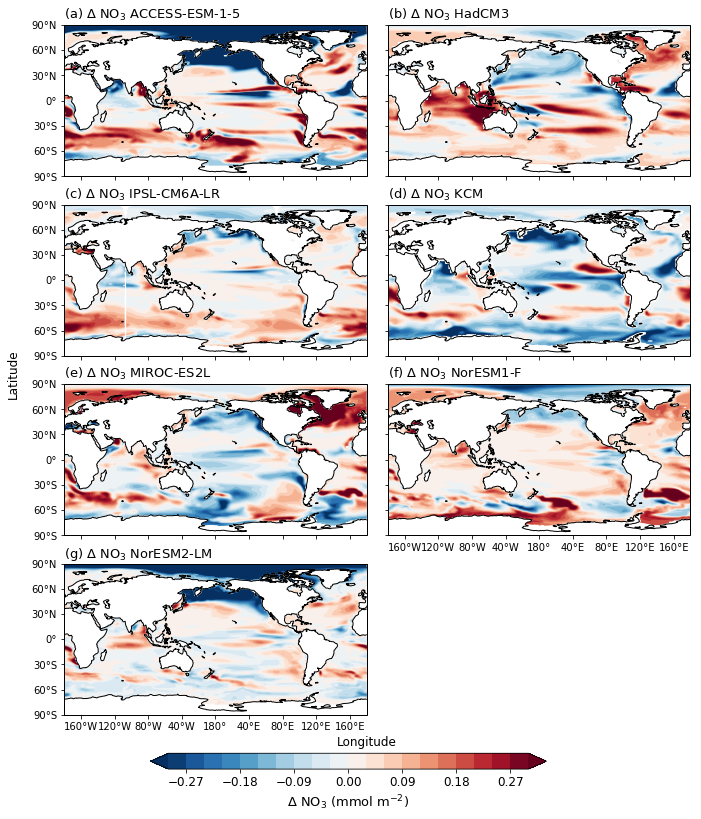

In [9]:
fig = plt.figure(figsize=(10, 11))
proj = ccrs.PlateCarree(central_longitude=180)
titles = ['ACCESS-ESM-1-5', 'HadCM3', 'IPSL-CM6A-LR', 'KCM', 'MIROC-ES2L', 'NorESM1-F', 'NorESM2-LM']
letters = ['(a)', '(b)','(c)','(d)','(e)','(f)','(g)', ]
sim = Dif_integrated
axes = []

for i in range(7):
    ax = fig.add_subplot(4, 2, i + 1, projection=proj)
    axes.append(ax)

for i, ax in enumerate(axes):
    ax.add_feature(cartopy.feature.COASTLINE)
    ax.set_global()
    ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
    ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)
    ax.set_yticks(np.arange(-90, 91, 30))
    ax.tick_params(axis='y', labelsize=10)
    ax.set_xticks([-160, -120, -80, -40, 0, 40, 80, 120, 160], crs=proj)
    ax.set_xticklabels(['160°W', '120°W', '80°W', '40°W', '180°', '40°E', '80°E', '120°E', '160°E'])
    ax.tick_params(axis='x', labelsize=10)
    
    col = i % 2                 
    bottom = (i == 5) or (i == 6) # lowest panel in each column

    ax.tick_params(axis='y', labelleft=(col == 0))
    ax.tick_params(axis='x', labelbottom=bottom)
    
    lev = np.arange(-0.3, 0.33, 0.03)
    ax.set_title(letters[i] +' Δ NO$_3$ ' + titles[i], fontsize=13, loc='left')
    im = iplt.contourf(sim[i]/1000, axes=ax, cmap='RdBu_r', levels = lev, extend='both')

# Colorbar
cbar_ax = fig.add_axes([0.2, 0.001, 0.55, 0.02]) # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ NO$_3$ (mmol m$^{-2}$)', size=13)
cbar.ax.tick_params(labelsize=12)
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.06, top=0.95, wspace=0.07, hspace=0.08)
# Shared axis labels
fig.text(0.001, 0.5, 'Latitude', va='center', rotation='vertical', fontsize=12)
fig.text(0.5, 0.03, 'Longitude', ha='center', fontsize=12)

#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/NO3_100m_int_diff.png', bbox_inches = 'tight', dpi=300, format='png')
plt.show()

### MMM

In [10]:
### MMM
no3_dif_100int = [cube.copy() for cube in Dif_integrated]
MMM_dif_100 = sum([no3_dif_100int[i].data for i in range(np.size(no3_dif_100int))])/7
MMM_dif_100_cube = no3_dif_100int[0].copy(data = MMM_dif_100)

In [11]:
#### Spread
sig_dif = []
for n in range(np.size(Dif_integrated)):
    difference = Dif_integrated[n].data
    # Only count differences with magnitude >= 1
    # 1 corresponds to (+) differences, -1 to (-) differences, 0 to no significant differences
    signed_diff = np.where(difference >= 0.00001, 1, np.where(difference <= -0.01, -1, 0))
    sig_dif.append(signed_diff)
# Sum
sum_sig_dif = np.sum(sig_dif, axis=0)
# Consensus
consensus_values = np.where(np.abs(sum_sig_dif) >= 5, sum_sig_dif, np.nan)
consensus_cube = MMM_dif_100_cube.copy(data=consensus_values)

non_consensus_mask = np.abs(sum_sig_dif) < 5
non_consensus_cube = MMM_dif_100_cube.copy(data=non_consensus_mask.astype(float))

Self-intersection at or near point -180 -5.390625
Self-intersection at or near point -180 -5.390625


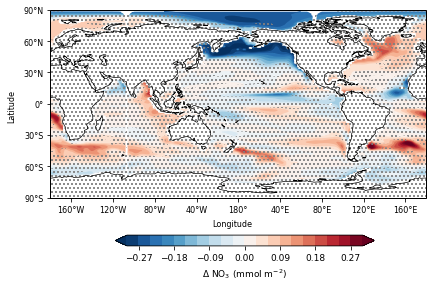

In [12]:
fig = plt.figure(figsize=(6, 5))
proj = ccrs.PlateCarree(central_longitude=180)
ax = fig.add_subplot(1, 1, 1, projection=proj)

ax.add_feature(cartopy.feature.COASTLINE, linewidth=0.7, edgecolor='k')
ax.set_global()
ax.yaxis.set_major_formatter(LATITUDE_FORMATTER)
ax.xaxis.set_major_formatter(LONGITUDE_FORMATTER)

ax.set_yticks(np.arange(-90, 91, 30))
ax.tick_params(axis='y', labelsize=8)
ax.set_xticks([-160, -120, -80, -40, 0, 40, 80, 120, 160], crs=ccrs.PlateCarree(central_longitude=180))
ax.set_xticklabels(['160°W', '120°W', '80°W', '40°W', '180°', '40°E', '80°E', '120°E', '160°E'])
ax.tick_params(axis='x', labelsize=8)
lev = np.arange(-0.3, 0.33, 0.03)
    
im = iplt.contourf(MMM_dif_100_cube/1000, axes = ax, cmap = 'RdBu_r', levels = lev, extend = 'both')
# Hatching Non consensus
iplt.contourf(non_consensus_cube, levels=[0.5, 1.5], colors='none', hatches=['...'], axes=ax)
mpl.rcParams['hatch.color'] = 'gray'
cf = iplt.contourf(non_consensus_cube, levels=[0.5, 1.5], colors='none', hatches=['...'], axes=ax)
# Title   
#ax.set_title('MMM (LIG-PI)', fontsize=15, loc='left')

# Colorbar
cbar_ax = fig.add_axes([0.23, 0.08, 0.6, 0.03]) # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Δ NO$_3$ (mmol m$^{-2}$)', size=9)
cbar.ax.tick_params(labelsize=9)
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.00, top=0.95, wspace=0.15, hspace=0.01)

fig.text(-0.02, 0.47, 'Latitude', va='center', rotation='vertical', fontsize=8)
fig.text(0.5, 0.135, 'Longitude', ha='center', fontsize=8)
#plt.savefig('/nfs/see-fs-01_users/mlzp121/Test_HadCM3_simulations/NO3_100m_int_dif_mmm.png', bbox_inches='tight', dpi=300, format='png')
plt.show()